## This code is to train RC on Stuart Landau system and use Jacobian eigenvalues to probe the transition in trained RC

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import networkx as nx
import math

## Building the reservoir computing architecture

In [2]:
class ReservoirComputer:
    
    def __init__(self, dim_system, dim_reservoir, rho, sigma):
        
        self.dim_system = dim_system
        self.dim_reservoir = dim_reservoir
        self.r_state = np.zeros(dim_reservoir)                                   
        self.A = generate_adjacency_matrix(dim_reservoir, rho, sigma)
        
        self.W_in = W_inn(dim_reservoir, dim_system)
        self.W_b = W_bb(dim_reservoir)
        self.W_out = np.zeros((dim_system, dim_reservoir))

    
    def advance_r_state(self, eps, u):
        alpha = 1
        self.r_state = ((1- alpha)* self.r_state) + alpha* np.tanh(np.matmul(self.A, self.r_state) + np.matmul(self.W_in, u.T) + 0.5223 * self.W_b * (eps))        # r_state is updated and stored as r(t+ delta t)
                                                                                   
        return self.r_state

    
    def train(self, trajectory_total, trajectory_new):                                                # Trajectory is the training data (initialized once model is called)
        
    
        R_total = np.empty((self.dim_reservoir, trajectory_total.shape[0]))
        eps_train = [3.75, 3.70, 3.65]

        div = int((trajectory_total.shape[0])/3)
        
        for m in range(len(eps_train)):

            self.r_state = np.zeros(self.dim_reservoir)
            
            for i in range(div*m , div + div*m):
                
                R_total[:, i] = self.r_state
                u = trajectory_total[i]                                                   # stores i th row by default
                self.advance_r_state(eps_train[m], u)

        range_removal = [(0,49),(16000,16049),(32000,32049)]
        column_removal = []
        for start, end in range_removal:
            column_removal.extend(range(start, end + 1))
        
        # Remove the specified columns
        R_total = np.delete(R_total, column_removal, axis=1)  #removing the r_state transient          
        
        self.W_out = linear_regression(R_total, trajectory_new)

        #print(self.W_out)                  #To check the trained weights

    def v(self):
        return np.transpose(np.matmul(self.W_out, self.r_state))                   # Gives the predicted output


    def predict(self, eps_new, steps, test_trajectory, train_trajectory):
        
        prediction = np.zeros((steps, self.dim_system))
        prediction[0] = test_trajectory[0,:]

        warmup = train_trajectory[0:50, :]                       # warmup of reservoir

        self.r_state = np.zeros(self.dim_reservoir)

        for l in range(50):

            self.advance_r_state(eps_new, warmup[l])
        
        for i in range(steps-1):
            
            self.advance_r_state(eps_new, prediction[i])
            v = self.v()
            prediction[i+1] = v
            
        return prediction

    def get_weights(self):
        return self.A, self.W_in, self.W_out, self.W_b

In [3]:
def W_bb(dim_reservoir):

    np.random.seed(36)
    W_b = (2* (np.random.rand(dim_reservoir)) - 1)* 2
    return W_b

def W_inn(dim_reservoir, dim_system):

    np.random.seed(85)
    W_in = np.zeros((dim_reservoir, dim_system))
    for i in range(dim_reservoir):
        
        W_in[i, math.floor(i*(dim_system/dim_reservoir))] = (2*np.random.random()-1)*2

    #W_in[:, dim_system] = (2*np.random.random((dim_reservoir))-1)*sigma
    return W_in

def generate_adjacency_matrix(dim_reservoir, rho, sigma):
    
    graph = nx.gnp_random_graph(dim_reservoir, sigma, seed = 47)                           # Generates an Erdos-Renyi graph of nodes = dim_reservoir and probab of node connection = sigma
    graph = nx.to_numpy_array(graph)

    # Ensure random_array is of the same shape as the graph adjacency matrix.
    np.random.seed(27)
    random_array = 2 * sigma* (np.random.rand(dim_reservoir, dim_reservoir) - 0.5)

    # Multiply graph adjacency matrix with random values.
    rescaled = graph * random_array
    return scale_matrix(rescaled, rho)


def scale_matrix(A, rho):
    eigenvalues, _ = np.linalg.eig(A)
    max_eigenvalue = np.amax(eigenvalues)
    A = A/np.absolute(max_eigenvalue) * rho                 #this makes the spectral radius of matrix A as rho
    return A

In [4]:
def linear_regression(R, trajectory, beta=0.0001):
    Rt = np.transpose(R)
    inverse_part = np.linalg.inv(np.matmul(R, Rt) + beta * np.identity(R.shape[0]))                # Tikhonov Regularization
    return np.matmul(np.matmul(trajectory.T, Rt), inverse_part)                           

## Coupled Stuart-Landau system

In [5]:
from scipy.integrate import odeint

def stuart_landau_derivative(y, t, omega, eps):
    x1, x2, y1, y2 = y[0], y[1], y[2], y[3]
    
    dx1dt = (1- x1**2 - y1**2)*x1 - omega[0]*y1 + eps*(x2 - x1)
    dx2dt = (1- x2**2 - y2**2)*x2 - omega[1]*y2 + eps*(x1 - x2)
    
    dy1dt = (1- x1**2 - y1**2)*y1 + omega[0]*x1 + eps*(y2 - y1)
    dy2dt = (1- x2**2 - y2**2)*y2 + omega[1]*x2 + eps*(y1 - y2)
    
    return [dx1dt, dx2dt, dy1dt, dy2dt]


In [6]:
dt = 0.05
timesteps = 36000
num_oscillators = 2

omega = np.array([2.0 , 7.0])

eps = [3.75, 3.70, 3.65, 3.63]


data_x_list = []
data_y_list = []

# Initial conditions
for eps in eps:
    
    #x0 = np.random.uniform(-0.5,0.5,num_oscillators)
    #y0 = np.random.uniform(-0.5,0.5,num_oscillators)

    x1_0 = 0.4
    x2_0 = -0.2
    y1_0 = 0.2
    y2_0 = -0.4
    y_initial = [x1_0, x2_0, y1_0, y2_0]
    time = np.linspace(0, timesteps * dt, timesteps)
    
    sol = odeint(stuart_landau_derivative, y_initial, time, args=(omega, eps)) 
   
    data_x_list.append(sol[:, :2])
    data_y_list.append(sol[:, 2:])

stacked_x = np.transpose(np.vstack(data_x_list))                               
stacked_y = np.transpose(np.vstack(data_y_list))                     
print(stacked_y.shape)
stacked_total = np.vstack((stacked_x, stacked_y))          
print(stacked_total.shape)

(2, 144000)
(4, 144000)


In [7]:
#train-test split

stacked_train = stacked_total[:, :-36000]
stacked_test = stacked_total[:, -16000:]            # selecting last 16000 columns

#print(stacked_train.shape)
# removing transient of first 20000 points each time
ranges_to_remove = [(0, 19999), (36000, 55999), (72000, 91999)]
columns_to_remove = []
for start, end in ranges_to_remove:
    columns_to_remove.extend(range(start, end + 1))


stacked_x_modified = np.delete(stacked_train, columns_to_remove, axis=1)
                 
training_data = np.transpose(stacked_x_modified)                

#print(training_data.shape)

# Remove the reservoir transient, 50 points each time
range_to_remove = [(0,49),(16000,16049),(32000,32049)]

column_to_remove = []
for start, end in range_to_remove:
    column_to_remove.extend(range(start, end + 1))

# Remove the specified columns
train_without_transient = np.transpose(np.delete(stacked_x_modified, column_to_remove, axis=1))            

#print(train_without_transient.shape)
valid_data = np.transpose(stacked_test)              


## Checking the prediction of RC

In [8]:
dim_reservoir = 300                                    
model = ReservoirComputer(4, dim_reservoir, 0.18, 0.03)      
model.train(training_data, train_without_transient)
predicted_data = model.predict(3.63,len(valid_data), valid_data, train_without_transient)              

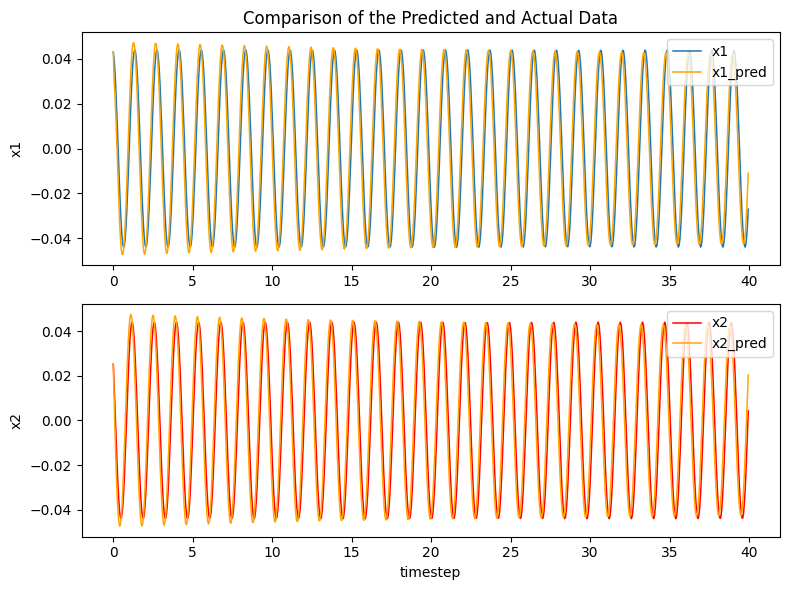

In [10]:
x1_data = valid_data[:,0]
x2_data = valid_data[:,1]


x1_pred = predicted_data[:,0]
x2_pred = predicted_data[:,1]

fig, axs = plt.subplots(2, 1, figsize=(8, 6))

timeaxis = np.arange(0, (valid_data.shape[0])*dt, dt)
# Plot data on each subplot

axs[0].plot(timeaxis[:800], x1_data[:800], label="x1", lw=1.1)
axs[0].plot(timeaxis[:800], x1_pred[:800], label="x1_pred", color='orange', lw=1.1)  
axs[0].set_ylabel("x1")
axs[0].set_title("Comparison of the Predicted and Actual Data")
axs[0].legend(loc='upper right')

axs[1].plot(timeaxis[:800], x2_data[:800], label="x2", color='r', lw=1.1)
axs[1].plot(timeaxis[:800], x2_pred[:800], label="x2_pred", color='orange', lw=1.1)  
axs[1].set_ylabel("x2")
axs[1].set_xlabel("timestep")
axs[1].legend(loc='upper right')

fig.tight_layout()
plt.show()

## Jacobian analysis

In [11]:
A, W_in, W_out, W_b = model.get_weights()

Lambda = A + np.matmul(W_in, W_out)
Omega = 0.5223 * W_b

# Finding the fixed points of the system

import numpy as np
from scipy.optimize import fsolve

# Number of variables/equations
num_variables = 300

def fixed_point_finder(epsilon_train):
    
    def dot_product(A, j, r):
    
        beta = 0
        for i in range(num_variables):
            beta = beta + A[j, i]* r[i]
        
        return beta
    
    # Define the function representing the system of equations
    def func(r):
        equations = []
        for i in range(num_variables):
            # System equations 
            eq = r[i] - np.tanh(epsilon_train * Omega[i] + dot_product(Lambda, i, r))
            equations.append(eq)
        return equations
    
    # Initial guess for the solution vector
    initial_guess = 0.5 * np.ones(num_variables)
    
    # Solve the system of equations
    solution = fsolve(func, initial_guess)
    
    return solution

#Eigenvalues

def eigen_tracker(epsilon_train, solution):
    Jacobian = np.empty((num_variables, num_variables))
    for j in range(num_variables):
        
        gamma = np.matmul(Lambda[j,:], solution) + epsilon_train * Omega[j]
        
        for k in range(num_variables):
            
            Jacobian[j,k] = (1 - np.tanh(gamma)**2)* Lambda[j, k]
    
    #print(Jacobian)
    
    eigenvalues = np.linalg.eigvals(Jacobian)
    #print(eigenvalues)
    mod_eig = np.abs(eigenvalues)
    #print(np.max(mod_eig))
    return eigenvalues, mod_eig

In [12]:
epsilon_list = np.array([3.35, 3.6, 4.2])
mod_eig_array = np.empty((num_variables,len(epsilon_list)))
eig_array = np.empty((num_variables,len(epsilon_list)), dtype=complex)
solution_array = np.empty((num_variables, len(epsilon_list)))

m = [1,2,3]
for m in m:

    solutionn = fixed_point_finder(epsilon_list[m-1])
    solution_array[:, m-1] = solutionn
    eig_array[:,m-1], mod_eig_array[:,m-1] = eigen_tracker(epsilon_list[m-1], solutionn)

## Plots for analysis

a) Represents Neimark-Sacker bifurcation: A complex conjugate pair crossing the unit circle.
b), c), d) show the Jacobian eigenvalues of RC at $\varepsilon$ = 3.35, 3.6, 4.2

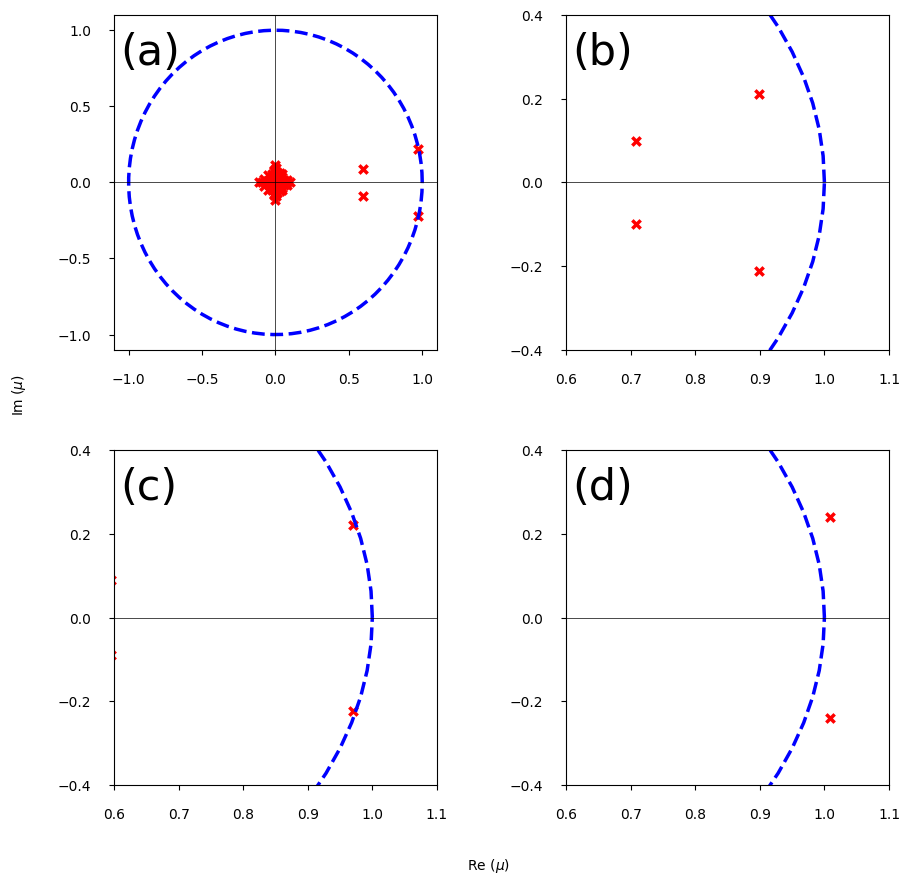

In [13]:
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
axs = axs.flatten()
m = [1,2,3]
labels = ['(b)', '(c)', '(d)']
for m in m:

    # Generate points for the unit circle
    theta = np.linspace(0, 2 * np.pi, 100)
    unit_circle_x = np.cos(theta)
    unit_circle_y = np.sin(theta)
    
    # Plotting
    axs[m].plot(unit_circle_x, unit_circle_y, 'b--', label='Unit Circle', lw = 2.5)  # Unit circle
    axs[m].scatter(np.real(eig_array[:,m-1]), np.imag(eig_array[:,m-1]), color='red', marker='x', label='Eigenvalues', lw = 2.5)  # Eigenvalues
    axs[m].axhline(0, color='black', lw=0.5)
    axs[m].axvline(0, color='black', lw=0.5)
    axs[m].set_xlim(0.6, 1.02)
    axs[m].set_ylim(-0.4,0.4)
    
    #axs[m].grid(True)
    #axs[m].axis('equal')  # Equal scaling for both axes

    axs[m].set_xticks(np.linspace(0.6, 1.1, 6))
    axs[m].set_yticks(np.linspace(-0.4, 0.4, 5))

    axs[m].tick_params(axis='both', which='major', pad=13)
    axs[m].text(0.02, 0.95, labels[m-1], transform=axs[m].transAxes, fontsize=31, verticalalignment='top')
    
axs[0].plot(unit_circle_x, unit_circle_y, 'b--', label='Unit Circle', lw = 2.5)  # Unit circle
axs[0].scatter(np.real(eig_array[:,1]), np.imag(eig_array[:,1]), color='red', marker='x', label='Eigenvalues', lw = 2.5)  # Eigenvalues
axs[0].axhline(0, color='black', lw=0.5)
axs[0].axvline(0, color='black', lw=0.5)

axs[0].set_xticks(np.linspace(-1, 1, 5))
axs[0].set_yticks(np.linspace(-1, 1, 5))
axs[0].tick_params(axis='both', which='major', pad=13)
axs[0].text(0.02, 0.95, '(a)', transform=axs[0].transAxes, fontsize=31, verticalalignment='top')
# Common x-axis label

fig.text(0.5, 0.03, r'Re ($\mu$)', ha='center', va='center')
fig.text(0.03, 0.5, r'Im ($\mu$)', ha='center', va='center', rotation='vertical')

plt.subplots_adjust(hspace=0.3, wspace=0.4)

plt.show()


## Fourier transform of the RC time series to extract the period

Frequency: 0.04 Hz, Magnitude: 306.89


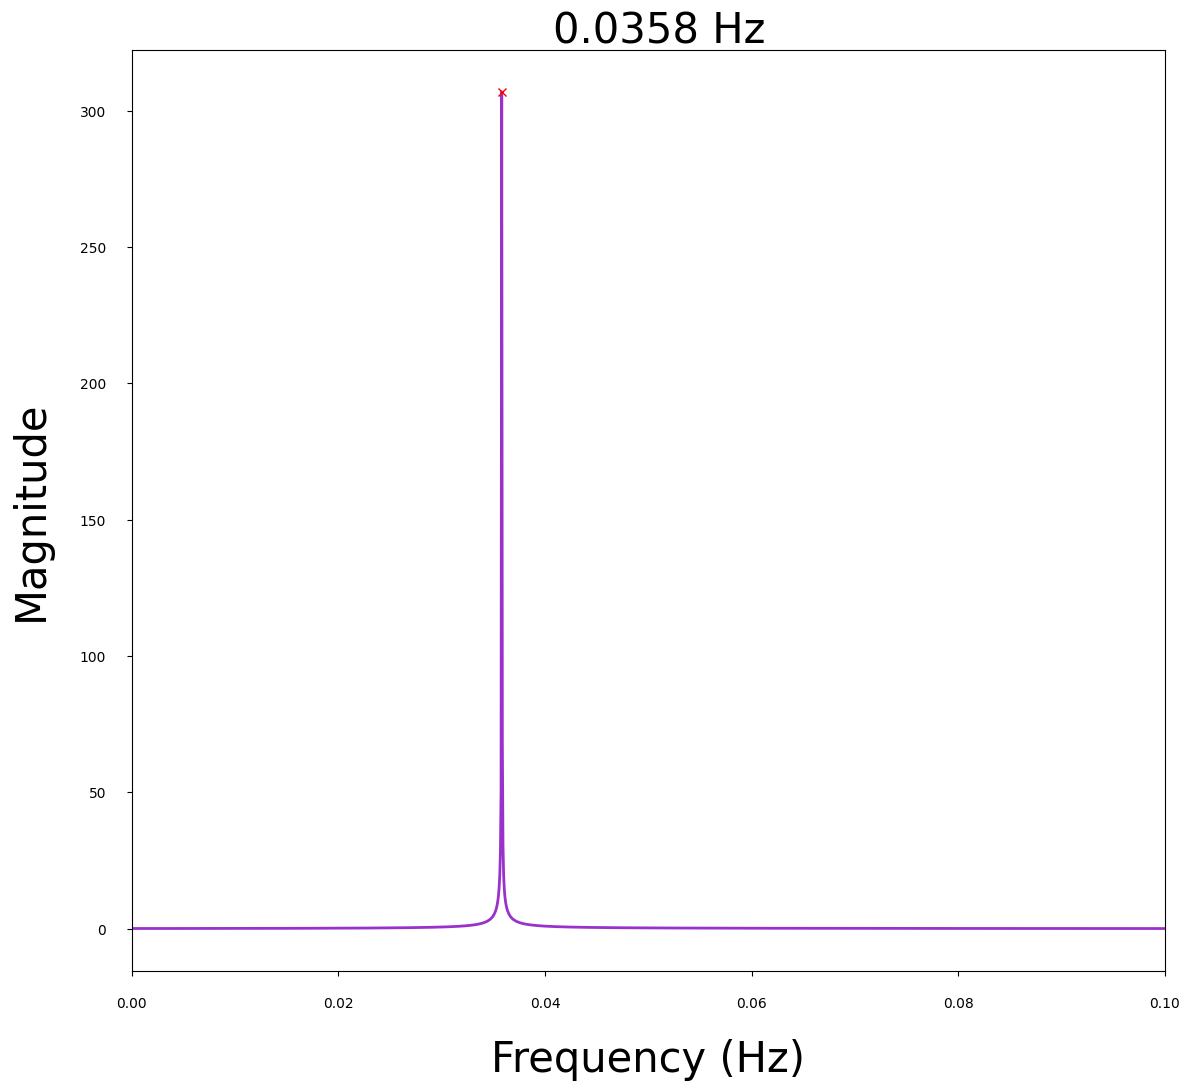

In [16]:
from scipy.signal import find_peaks
import numpy as np
import matplotlib.pyplot as plt

time_series = x1_pred

# Perform Fourier Transform
fft_result = np.fft.fft(time_series)

# Calculate the frequencies corresponding to the FFT result
sampling_rate = 1  # Sampling rate in Hz (for example, 100 samples per second)
frequencies = np.fft.fftfreq(len(time_series), d=1)

# Only consider the positive frequencies
positive_frequencies = frequencies[:len(frequencies)//2]
magnitude_spectrum = np.abs(fft_result)[:len(frequencies)//2]

# Find peaks in the magnitude spectrum
peaks, _ = find_peaks(magnitude_spectrum, height=200)              # height can be adjusted based on the prominence of peaks

# Get the frequencies at the peaks
peak_frequencies = positive_frequencies[peaks]
peak_magnitudes = magnitude_spectrum[peaks]

# Print the peak frequencies and their magnitudes
for freq, mag in zip(peak_frequencies, peak_magnitudes):
    print(f"Frequency: {freq:.2f} Hz, Magnitude: {mag:.2f}")

# Plot the magnitude spectrum with peaks marked
plt.figure(figsize=(12, 11))
plt.plot(positive_frequencies, magnitude_spectrum, label='Magnitude Spectrum', color='darkorchid', lw = 2)
plt.plot(peak_frequencies, peak_magnitudes, 'x', label='Peaks', color='red')

y_offsets = [325,900]
for i in range(len(peak_frequencies)):
    plt.annotate(f'{peak_frequencies[i]:.4f} Hz', 
                 xy=(peak_frequencies[i], peak_frequencies[i]), 
                 xytext=(peak_frequencies[i]+0.005, frequencies[i]+y_offsets[i]),  # Adjust this value for better positioning
                 fontsize=30, color='black')



plt.xlabel('Frequency (Hz)', fontsize=30, labelpad=20)
plt.ylabel('Magnitude', fontsize=30, labelpad=20)
plt.xlim(0, 0.1)                     # Scale the x-axis to show frequencies up to 15 Hz
plt.tick_params(axis='both', which='major', pad=15)
plt.tight_layout()
plt.show()

Eigenvalue 1 : (0.9707229763195118+0.2220474162842216j)
Eigenvalue 2 : (0.9707229763195118-0.2220474162842216j)

|λ₁| = 0.995795
|λ₂| = 0.995795

θ₁ = 0.224876 freq = 0.0358
θ₂ = -0.224876 freq= -0.0358


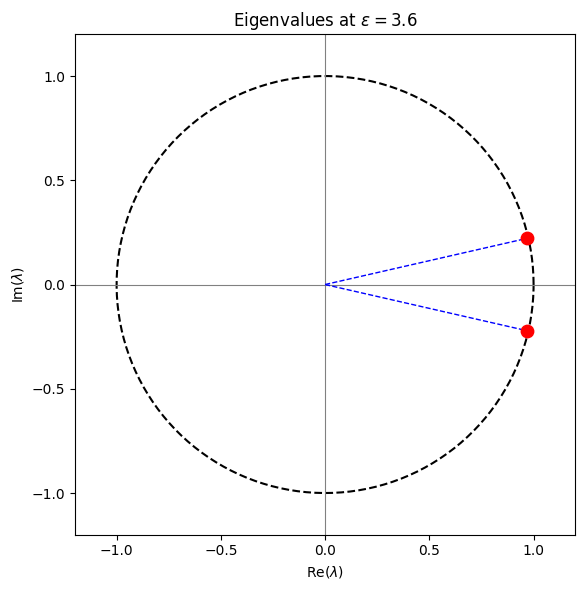

In [19]:

# epsilon = 3.6
idx = np.where(np.isclose(epsilon_list, 3.6))[0][0]

eigvals = eig_array[:, idx]
modulus = mod_eig_array[:, idx]

# Two eigenvalues whose modulus is closest to 1
indices = np.argsort(np.abs(modulus - 1))[:2]
eig_pair = eigvals[indices]

theta = np.angle(eig_pair)

print(f"Eigenvalue 1 : {eig_pair[0]}")
print(f"Eigenvalue 2 : {eig_pair[1]}\n")

print(f"|λ₁| = {np.abs(eig_pair[0]):.6f}")
print(f"|λ₂| = {np.abs(eig_pair[1]):.6f}\n")

print(f"θ₁ = {theta[0]:.6f} freq = {theta[0]/(2*np.pi):.4f}")
print(f"θ₂ = {theta[1]:.6f} freq= {theta[1]/(2*np.pi):.4f}")

# Plot
fig, ax = plt.subplots(figsize=(6, 6))

t = np.linspace(0, 2*np.pi, 300)

ax.plot(np.cos(t), np.sin(t),
        'k--',
        label='Unit Circle')

ax.axhline(0, color='gray', lw=0.8)
ax.axvline(0, color='gray', lw=0.8)

ax.scatter(eig_pair.real,
           eig_pair.imag,
           color='red',
           s=80,
           zorder=5)

for lam in eig_pair:
    ax.plot([0, lam.real],
            [0, lam.imag],
            'b--',
            lw=1)

ax.set_xlabel(r'Re($\lambda$)')
ax.set_ylabel(r'Im($\lambda$)')
ax.set_title(r'Eigenvalues at $\epsilon=3.6$')
ax.set_aspect('equal')
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)

plt.tight_layout()
plt.show()